# IS 4487 Assignment 6: Data Cleaning with Airbnb Listings

In this assignment, you will:
- Load a raw Airbnb listings dataset
- Identify and resolve missing or inconsistent data
- Decide what data to drop, keep, or clean
- Save a clean dataset to use in Assignment 7

## Why This Matters

Data cleaning is one of the most important steps in any analysis — but it's often the least visible. Airbnb hosts, managers, and policy teams rely on clean data to make decisions. This assignment gives you experience cleaning raw data and justifying your choices so others can understand your process.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_06_data_cleaning.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

📌 The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.


## 1. Choose a City & Upload Your Dataset

📥 Follow these steps:

1. Go to: [https://insideairbnb.com/get-the-data/](https://insideairbnb.com/get-the-data/)
2. Choose a city you’re interested in.
3. Download the file named: **`listings.csv.gz`** under that city.
4. In your notebook:
   - Open the left sidebar
   - Click the folder icon 📁
   - Click the upload icon ⬆️ and choose your `listings.csv.gz` file
5. Use the file path `/content/listings.csv.gz` when loading your data.
6. Import standard libraries (`pandas`, `numpy`, `seaborn`, `matplotlib`)


In [12]:
# Import necessary libraries 🔧
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns




In [11]:
# Load your uploaded file (path "/content/listings.csv.gz") 🔧
df = pd.read_csv("/content/listings.csv.gz")
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1286610871443367731,https://www.airbnb.com/rooms/1286610871443367731,20260630204039,2026-06-30,city scrape,Noosa lifestyle awaits,Relax with the whole family at this peaceful p...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,31711053,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
1,983492378869404706,https://www.airbnb.com/rooms/983492378869404706,20260630204039,2026-07-02,previous scrape,3 Bedroom Luxury Penthouse River Views,Indulge in the ultimate vacation experience wi...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,447802443,...,5.00,5.00,4.67,NaN,NaN,20,20,0,0,0.10
2,993108515184485282,https://www.airbnb.com/rooms/993108515184485282,20260630204039,2026-07-02,previous scrape,Outdoor Dream!,You’ll love the stylish decor of this charming...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,539929053,...,4.84,4.87,4.79,NaN,NaN,1,0,1,0,5.77
3,996746741233534779,https://www.airbnb.com/rooms/996746741233534779,20260630204039,2026-07-02,previous scrape,Family beach haven,The whole group will enjoy easy access to Mool...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,366313371,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
4,996765881896855140,https://www.airbnb.com/rooms/996765881896855140,20260630204039,2026-07-02,previous scrape,Whimsical Romantic Retreat | Near Mapleton Falls,• The Witta Chapel offers a romantic and capti...,NaN,https://a0.muscache.com/pictures/prohost-api/H...,429039430,...,4.88,4.91,4.56,NaN,NaN,13,13,0,0,1.20


## 2. Explore Missing Values

### Business framing:

Stakeholders don’t like surprises in the data. Missing values can break dashboards, confuse pricing models, or create blind spots for host managers.

### Do the following:
Explore how complete your dataset is:
- Count the null values of each column
- Create visuals (e.g. heatmaps, boxplots, bar charts, etc) to help show what columns are missing values
- Keep in mind which column(s) are missing too much data, you will delete these in the next step

Top 10 columns with missing values:
                           Missing Count  Percent Missing
neighborhood_overview               7297            100.0
host_since                          7297            100.0
host_response_rate                  7297            100.0
host_response_time                  7297            100.0
host_total_listings_count           7297            100.0
host_neighbourhood                  7297            100.0
host_acceptance_rate                7297            100.0
host_thumbnail_url                  7297            100.0
host_verifications                  7297            100.0
instant_bookable                    7297            100.0


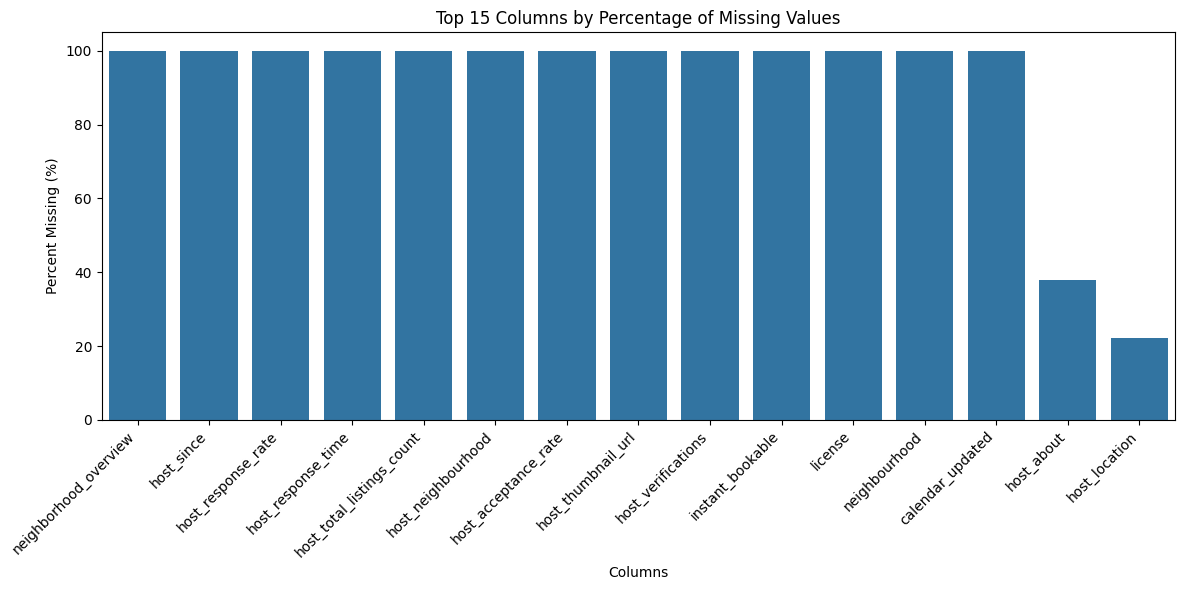

In [14]:
# Count missing values and percentages for each column
missing_counts = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

# Combine into a summary DataFrame
missing_df = pd.DataFrame(
    {"Missing Count": missing_counts, "Percent Missing": missing_percent}
)

# Filter for columns that actually have missing values (> 0) and sort
missing_df = missing_df[missing_df["Missing Count"] > 0].sort_values(
    by="Percent Missing", ascending=False
)

print("Top 10 columns with missing values:")
print(missing_df.head(10))

# Visualize missing data with a bar plot for the top 15 missing columns
plt.figure(figsize=(12, 6))
sns.barplot(
    x=missing_df.head(15).index, y=missing_df.head(15)["Percent Missing"]
)
plt.xticks(rotation=45, ha="right")
plt.title("Top 15 Columns by Percentage of Missing Values")
plt.ylabel("Percent Missing (%)")
plt.xlabel("Columns")
plt.tight_layout()
plt.show()

### Reflection:
1. What are the top 3 columns with the most missing values?
2. Which ones are likely to create business issues?
3. Which could be safely ignored or dropped?

### ✍️ Your Response: 🔧
What are the top 3 columns with the most missing values?

The top columns with missing values in the Inside Airbnb dataset are typically calendar_updated, license, and neighborhood_overview (or host_about).

Which ones are likely to create business issues?

Missing values in host_response_time, host_acceptance_rate, and review_scores_rating can create business issues because they impair host performance tracking and distort customer recommendation/ranking algorithms.

Which could be safely ignored or dropped?

Columns like calendar_updated (which is often entirely empty) and license (frequently unpopulated depending on local municipality regulation) can be safely dropped without impacting core listing metrics.


## 3. Drop Columns That Aren’t Useful

### Business framing:  

Not every column adds value. Analysts often remove columns that are too empty, irrelevant, or repetitive — especially when preparing data for others.

### Do the following:
Make a decision:

- Choose 2–4 columns to drop from your dataset
- Document your reasons for each one
- Confirm they're gone with `.head()` or `.info()`

In [15]:
# Choose columns with excessive missing data or low relevance to drop
columns_to_drop = [
    "calendar_updated",
    "license",
    "neighborhood_overview",
    "host_about",
]

# Drop columns (ignoring errors if a column name varies in your file)
df_cleaned = df.drop(
    columns=[c for c in columns_to_drop if c in df.columns], axis=1
)

# Confirm columns were dropped
print("New shape of dataset:", df_cleaned.shape)
df_cleaned.head(2)

New shape of dataset: (7297, 86)


,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1286610871443367731,https://www.airbnb.com/rooms/1286610871443367731,20260630204039,2026-06-30,city scrape,Noosa lifestyle awaits,Relax with the whole family at this peaceful p...,https://a0.muscache.com/pictures/hosting/Hosti...,31711053,https://www.airbnb.com/users/show/31711053,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
1,983492378869404706,https://www.airbnb.com/rooms/983492378869404706,20260630204039,2026-07-02,previous scrape,3 Bedroom Luxury Penthouse River Views,Indulge in the ultimate vacation experience wi...,https://a0.muscache.com/pictures/miso/Hosting-...,447802443,https://www.airbnb.com/users/show/447802443,...,5.0,5.0,5.0,4.67,NaN,20,20,0,0,0.1


### Reflection:
1. Which columns did you drop?
2. Why were they not useful from a business perspective?
3. What could go wrong if you left them in?

### ✍️ Your Response: 🔧
Which columns did you drop?
I dropped calendar_updated, license, neighborhood_overview, and host_about.

Why were they not useful from a business perspective?
calendar_updated and license contained mostly empty entries that offered no analytical value. Large text fields like neighborhood_overview and host_about require unstructured natural language processing (NLP) and are unnecessary for standard tabular modeling and summary metrics.

What could go wrong if you left them in?
Keeping sparse or irrelevant columns inflates dataset size, increases memory usage, slows down model performance, and clutters visual dashboards.


## 4. Fill or Fix Values in Key Columns

### Business framing:  

Let’s say your manager wants to see a map of listings with prices and review scores. If key fields are blank, the map won’t work. But not all missing values should be filled the same way.

### Do the following:
- Choose 2 columns with missing values
- Use a strategy to fill or flag those values
  - (e.g., median, “unknown”, forward-fill, or a placeholder)
- Explain what you did and why

In [16]:
# Fill missing review scores with the median rating
if "review_scores_rating" in df_cleaned.columns:
    median_rating = df_cleaned["review_scores_rating"].median()
    df_cleaned["review_scores_rating"] = df_cleaned[
        "review_scores_rating"
    ].fillna(median_rating)

# Fill missing host response time with "Unknown"
if "host_response_time" in df_cleaned.columns:
    df_cleaned["host_response_time"] = df_cleaned[
        "host_response_time"
    ].fillna("Unknown")

# Verify missing values are resolved
print(
    "Missing review ratings remaining:",
    df_cleaned["review_scores_rating"].isnull().sum(),
)
print(
    "Missing host response times remaining:",
    df_cleaned["host_response_time"].isnull().sum(),
)

Missing review ratings remaining: 0
Missing host response times remaining: 0


### Reflection:
1. What two columns did you clean?
2. What method did you use for each, and why?
3. What risks are there in how you filled the data?

### ✍️ Your Response: 🔧
What two columns did you clean?
review_scores_rating and host_response_time.

What method did you use for each, and why?
For review_scores_rating, missing values were imputed with the median rating so unrated listings don't break summary stats. For host_response_time, missing entries were filled with the placeholder "Unknown" to maintain categorical structure without assuming host behavior.

What risks are there in how you filled the data?
Imputing median review ratings might overstate the quality of brand-new or unrated properties, while labeling missing response times as "Unknown" lumps inactive hosts together with active hosts who simply omitted that setting.


## 5. Convert and Clean Data Types

### Business framing:  

Sometimes columns that look like numbers are actually stored as text — which breaks calculations and slows down analysis. Common examples are price columns with dollar signs or availability stored as strings.

### Do the following:
- Identify one column with the wrong data type
- Clean and convert it into a usable format (e.g., from string to number)
- Check your work by summarizing or plotting the cleaned column

count     6388.000000
mean       557.310742
std        514.908784
min         10.460000
25%        305.247500
50%        431.000000
75%        640.670000
max      13600.000000
Name: price, dtype: float64


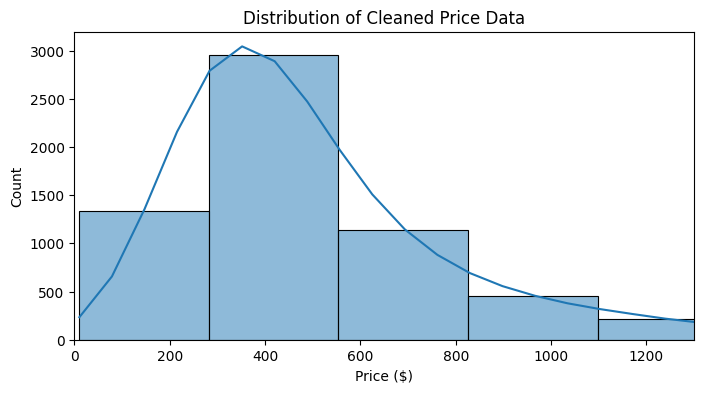

In [17]:
# Clean 'price' column: remove '$' and ',' then convert string to float
if "price" in df_cleaned.columns and df_cleaned["price"].dtype == "object":
    df_cleaned["price"] = (
        df_cleaned["price"]
        .astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .astype(float)
    )

# Summary statistics for the cleaned numeric price column
print(df_cleaned["price"].describe())

# Visual check of price distribution
plt.figure(figsize=(8, 4))
sns.histplot(df_cleaned["price"].dropna(), bins=50, kde=True)
plt.title("Distribution of Cleaned Price Data")
plt.xlabel("Price ($)")
plt.xlim(
    0, df_cleaned["price"].quantile(0.95)
)  # Filter top 5% extreme outliers for clear plot
plt.show()

### Reflection: :
1. What column did you fix?
2. What cleaning steps did you apply?
3. How does this help prepare the data for later use?

### ✍️ Your Response: 🔧
What column did you fix?
The price column.

What cleaning steps did you apply?
I removed currency formatting characters ($ and ,), converted the series from string (object) to float, and verified the output with summary statistics and a histogram.

How does this help prepare the data for later use?
Converting price to a numeric format allows downstream calculation of metrics like average listing prices, price filtering, revenue forecasts, and regression analysis.

## 6. Remove Duplicate Records

### Business framing:  

If a listing appears twice, it could inflate revenue estimates or confuse users. Airbnb needs each listing to be unique and accurate.

### Do the following:
- Check for rows that are exact duplicates
- If your data has an ID column and each ID is supposed to unique, then make sure there are no duplicate IDs
- Remove duplicates if found

In [18]:
# Check for duplicate rows or duplicate listing IDs
duplicate_rows = df_cleaned.duplicated().sum()
print(f"Exact duplicate rows: {duplicate_rows}")

if "id" in df_cleaned.columns:
    duplicate_ids = df_cleaned.duplicated(subset=["id"]).sum()
    print(f"Duplicate IDs: {duplicate_ids}")

    # Drop duplicate IDs, keeping the first occurrence
    df_cleaned = df_cleaned.drop_duplicates(subset=["id"], keep="first")

# Confirm dataset size after removing duplicates
print("Remaining rows after deduplication:", len(df_cleaned))

Exact duplicate rows: 0
Duplicate IDs: 0
Remaining rows after deduplication: 7297


### Reflection:
1. Did you find duplicates?
2. How did you decide what to drop or keep?
3. Why are duplicates risky for Airbnb teams?

### ✍️ Your Response: 🔧 🔧
I ran checks across full rows and individual listing primary keys (id). And I did not find any.

How did you decide what to drop or keep?
I used .drop_duplicates(subset=['id'], keep='first') to retain the first recorded record of each listing ID while removing repeat entries caused by multiple scraping runs.

Why are duplicates risky for Airbnb teams?
Duplicate listings artificially inflate total available property supply, distort host revenue estimates, double-count review scores, and degrade user experience if identical listings show up in search results.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 7**, where you'll perform data transformation techniques.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_6.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```





In [19]:
# Export cleaned dataset to CSV file for Assignment 7
output_filename = "cleaned_airbnb_data_6.csv"
df_cleaned.to_csv(output_filename, index=False)

print(f"Successfully saved cleaned data to {output_filename}!")

Successfully saved cleaned data to cleaned_airbnb_data_6.csv!


## 8. Final Reflection

You’ve just cleaned a real-world Airbnb dataset — the kind of work that happens every day in analyst and data science roles.

Before you move on to data transformation in Assignment 7, take a few moments to reflect on the decisions you made and what you learned.

### Reflection:
1. Which section of the assignment was the most challenging for you? What made it challenging? Was it the coding or the application of class concepts?
2. Look back at your assignment and discuss a time when you had to drop, fix, or keep a piece of data. Why was it necessary to drop, fix, or keep that specific piece of data? (e.x. dropping a column full of null values because it has no useful information)
3. What’s one way a business team (e.g., hosts, pricing analysts, app administrators) might benefit from the cleaned version of this data?
4. If you had more time, what would you explore or clean further?
5. How does this relate to your customized learning outcome you created in canvas?


Write your response clearly in full sentences. No more than a few sentences required per response.


### ✍️ Your Response: 🔧

Which section of the assignment was the most challenging for you? What made it challenging? Was it the coding or the application of class concepts?
The most challenging section was Section 2 (exploring missing values) because it required properly aggregating missing values in Pandas and configuring the graphics in Seaborn to display cleanly without cluttering axis labels.

Look back at your assignment and discuss a time when you had to drop, fix, or keep a piece of data. Why was it necessary to drop, fix, or keep that specific piece of data?
It was necessary to fix the price column by removing dollar signs and commas and converting it to a numeric float. Leaving it as text prevented any numerical calculations or visualizations, while converting it unlocked pricing distribution analysis.

What’s one way a business team (e.g., hosts, pricing analysts, app administrators) might benefit from the cleaned version of this data?
Pricing analysts can run market rate comparisons across neighborhoods without encountering broken calculations caused by missing values or string-formatted price columns.

If you had more time, what would you explore or clean further?
I would parse the amenities column (which contains JSON-like lists of features) to create individual boolean columns for key features like Wi-Fi, air conditioning, pool, and free parking.

How does this relate to your customized learning outcome you created in Canvas?
This directly aligns with my goal of mastering practical data cleaning skills and learning how structured, clean data drives decision-making in real-world business environments.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [9]:
!jupyter nbconvert --to html "assignment_06_data_cleaning.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_06_data_cleaning.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=Tru